# 07 Explainability

Final ET (core, full) and San + SVR hybrid models refit on all 22 days. SHAP and ALE effects are associations; speed and mixing time are confounded with the day.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import json
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import shap

from src.config import DATA_PROC, RESULTS, SED_TIMES
from src.features import make_table
from src import models as M
from src import hybrid as H
from src import kinetics as kin
from src import style

style.apply()
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.width", 160)

N_TRIALS = 15
CORE = ["dose", "log_t0_raw", "sed"]
FULL = CORE + ["speed", "mtime"]
HF = ["dose", "log_t0_raw"]
TIMES = SED_TIMES[1:]
MET = RESULTS / "metrics"

## 1. Final models

In [2]:
long = pd.read_csv(DATA_PROC / "long.csv", parse_dates=["date"])
tab = make_table(long, level="cell")
y = tab["log_ratio"].to_numpy()
groups = tab["day"].to_numpy()
X = {"core": tab[CORE].to_numpy(float), "full": tab[FULL].to_numpy(float)}

et = {}
for fs, feats in [("core", CORE), ("full", FULL)]:
    p = M.tune("et", X[fs], y, groups, "lodo", feats, N_TRIALS)
    et[fs] = M.make("et", p, feats).fit(X[fs], y)
    print(f"et {fs}: {p}")

jars = tab.drop_duplicates("run").set_index("run").sort_index()
Yj = tab.pivot(index="run", columns="sed", values="log_ratio").loc[jars.index, TIMES].to_numpy()
fits = pd.read_csv(DATA_PROC / "kinetic_fits.csv")
Z = H.to_targets(fits[fits["model"] == "san"].set_index("run").loc[jars.index, ["tau", "b"]].to_numpy(), "san")
Xj = jars[HF].to_numpy(float)
p = H.tune("svr", "san", Xj, Z, Yj, jars["day"].to_numpy(), TIMES, HF, N_TRIALS)
hyb = H.make_reg("svr", p, HF).fit(Xj, Z)
print(f"hybrid san + svr: {p}")


def hyb_params(Xh):
    return H.from_targets(hyb.predict(Xh), "san")


def hyb_predict(Xc):
    P = hyb_params(Xc[:, :2])
    return np.log10(kin.san(Xc[:, 2], 1.0, P[:, 0], P[:, 1]))


MODELS = {"ET core": (et["core"].predict, CORE, "core"),
          "ET full": (et["full"].predict, FULL, "full"),
          "Hybrid San + SVR": (hyb_predict, CORE, "core")}
for name, (f, _, fs) in MODELS.items():
    print(f"{name:18s} training RMSE: {np.sqrt(np.mean((f(X[fs]) - y) ** 2)):.4f}")

et core: {'max_features': 0.602361513049481, 'min_samples_leaf': 6, 'max_depth': None}
et full: {'max_features': 0.7941499231087676, 'min_samples_leaf': 1, 'max_depth': 8}
hybrid san + svr: {'C': 3.4890188454913864, 'gamma': 0.05987474910461398, 'epsilon': 0.001238513729886093}
ET core            training RMSE: 0.1152
ET full            training RMSE: 0.0601
Hybrid San + SVR   training RMSE: 0.1468


## 2. SHAP attributions (target: log10(T/T0,raw))

In [3]:
sv, ex = {}, {}
for name, (f, feats, fs) in MODELS.items():
    if name.startswith("ET"):
        e = shap.TreeExplainer(et[fs])(X[fs])
        e.feature_names = feats
    else:
        bg = shap.sample(X[fs], 100, random_state=0)
        e = shap.Explainer(f, shap.maskers.Independent(bg), feature_names=feats)(X[fs])
    ex[name], sv[name] = e, e.values

imp = pd.DataFrame({name: pd.Series(np.abs(v).mean(0), index=MODELS[name][1]) for name, v in sv.items()})
share = (imp / imp.sum()).round(3)
imp.round(4)

ExactExplainer explainer: 1009it [00:36, 24.31it/s]                          


,ET core,ET full,Hybrid San + SVR
dose,0.0609,0.0401,0.0913
log_t0_raw,0.1464,0.1736,0.1946
mtime,NaN,0.0299,NaN
sed,0.1148,0.1255,0.1384
speed,NaN,0.0550,NaN


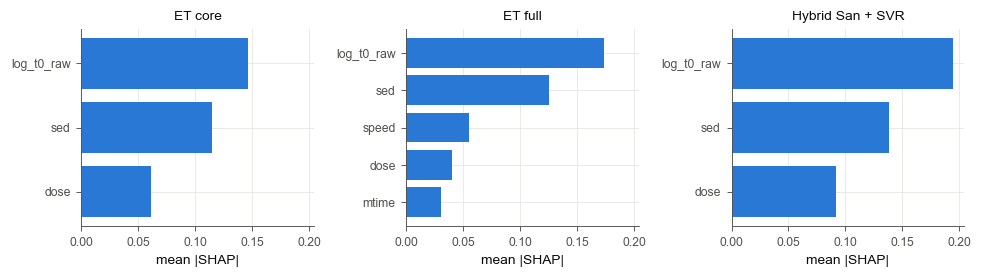

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(9, 2.6), sharex=True)
for ax, (name, col) in zip(axes, imp.items()):
    c = col.dropna().sort_values()
    ax.barh(c.index, c.values, color=style.COLORS[0])
    ax.set_title(name)
    ax.set_xlabel("mean |SHAP|")
fig.tight_layout()
style.save(fig, "fig01_shap_importance", "xai")
plt.show()

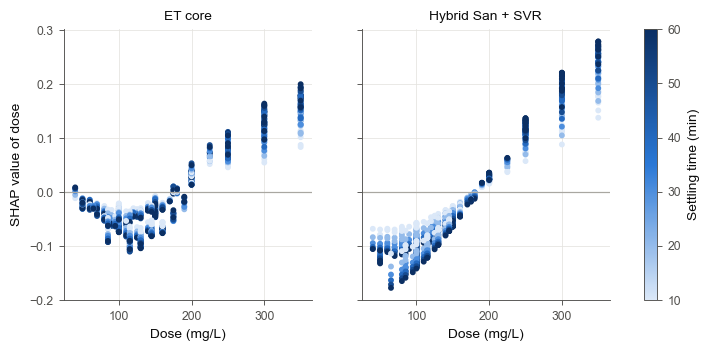

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), sharey=True)
for ax, name in zip(axes, ["ET core", "Hybrid San + SVR"]):
    j = CORE.index("dose")
    sc = ax.scatter(X["core"][:, j], sv[name][:, j], c=X["core"][:, CORE.index("sed")], cmap=style.SEQ, s=8)
    ax.axhline(0, color=style.MUTED, lw=0.8)
    ax.set_title(name)
    ax.set_xlabel("Dose (mg/L)")
axes[0].set_ylabel("SHAP value of dose")
fig.colorbar(sc, ax=axes, label="Settling time (min)")
style.save(fig, "fig02_shap_dose", "xai")
plt.show()

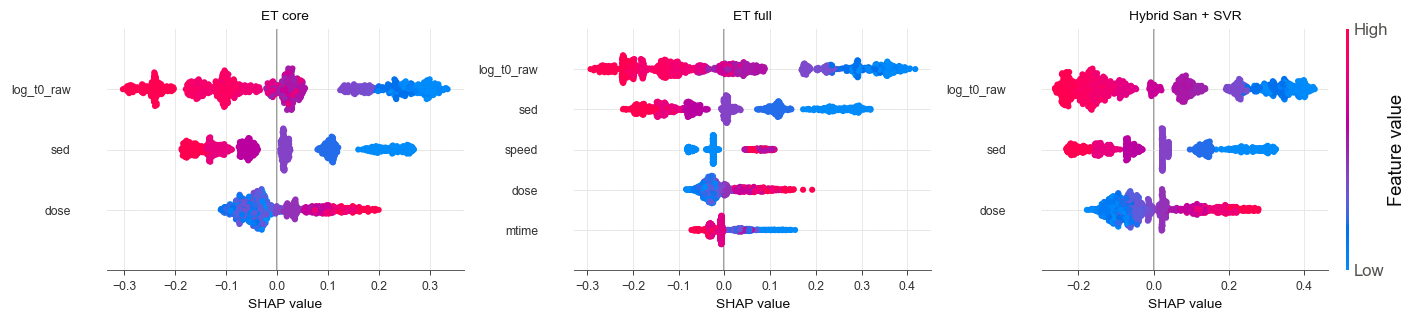

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, (name, e) in zip(axes, ex.items()):
    shap.plots.beeswarm(e, ax=ax, show=False, color_bar=ax is axes[-1], plot_size=None)
    ax.set_title(name)
    ax.set_xlabel("SHAP value", fontsize=9)
    ax.tick_params(labelsize=8)
fig.tight_layout()
style.save(fig, "fig05_shap_beeswarm", "xai")
plt.show()

Waterfall for one jar at 60 min: the first jar at the highest dose tested (350 mg/L).

{'day': 0.0, 'dose': 350.0, 't0_raw': 219.66666666666666, 'sed': 60.0, 'log_ratio': -0.5869063877625056}


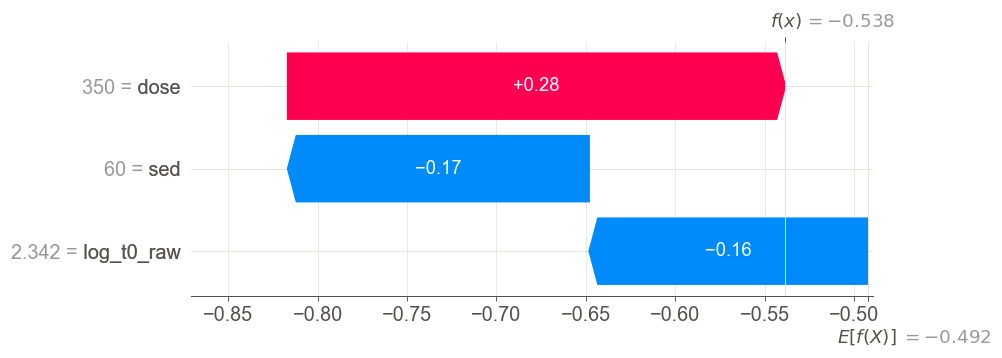

In [7]:
i = tab.loc[tab["sed"] == 60, "dose"].idxmax()
print(tab.loc[i, ["day", "dose", "t0_raw", "sed", "log_ratio"]].to_dict())
shap.plots.waterfall(ex["Hybrid San + SVR"][i], show=False)
fig = plt.gcf()
style.save(fig, "fig06_shap_waterfall", "xai")
plt.show()

## 3. Accumulated local effects

In [8]:
def ale(f, Xa, j, bins=10):
    x = Xa[:, j]
    edges = np.unique(np.quantile(x, np.linspace(0, 1, bins + 1)))
    k = np.clip(np.searchsorted(edges, x) - 1, 0, len(edges) - 2)
    lo, hi = Xa.copy(), Xa.copy()
    lo[:, j], hi[:, j] = edges[k], edges[k + 1]
    eff = pd.Series(f(hi) - f(lo)).groupby(k).mean().reindex(range(len(edges) - 1), fill_value=0)
    a = np.r_[0, eff.cumsum()]
    n = np.bincount(k, minlength=len(edges) - 1)
    a -= ((a[:-1] + a[1:]) / 2 * n).sum() / n.sum()
    return edges, a


ale_rows = []
for name, (f, feats, fs) in MODELS.items():
    for j, feat in enumerate(feats):
        e, a = ale(f, X[fs], j)
        ale_rows += [{"model": name, "feature": feat, "x": xi, "ale": ai} for xi, ai in zip(e, a)]
ale_tab = pd.DataFrame(ale_rows)
ale_tab.groupby(["feature", "model"])["ale"].agg(lambda s: s.max() - s.min()).unstack().round(3)

model,ET core,ET full,Hybrid San + SVR
feature,,,
dose,0.207,0.139,0.346
log_t0_raw,0.522,0.490,0.579
mtime,NaN,0.126,NaN
sed,0.355,0.392,0.424
speed,NaN,0.097,NaN


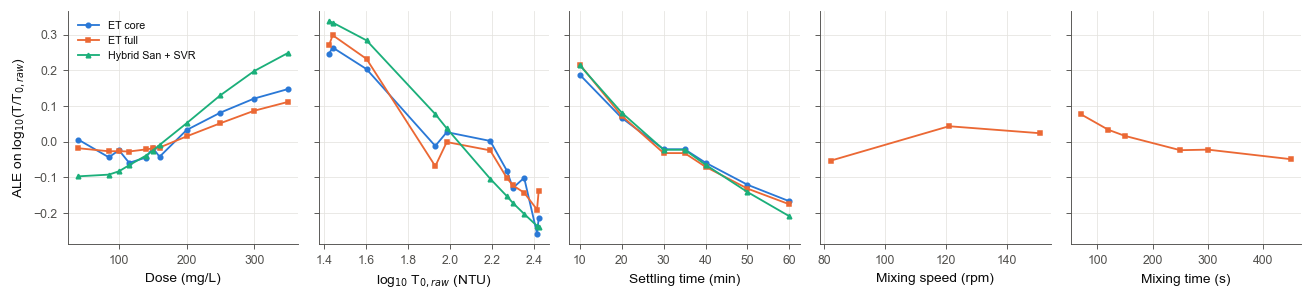

In [9]:
labels = {"dose": "Dose (mg/L)", "log_t0_raw": "log$_{10}$ T$_{0,raw}$ (NTU)", "sed": "Settling time (min)",
          "speed": "Mixing speed (rpm)", "mtime": "Mixing time (s)"}
fig, axes = plt.subplots(1, 5, figsize=(12, 2.8), sharey=True)
for ax, feat in zip(axes, FULL):
    for i, name in enumerate(MODELS):
        d = ale_tab[(ale_tab["model"] == name) & (ale_tab["feature"] == feat)]
        if len(d):
            ax.plot(d["x"], d["ale"], marker=style.MARKERS[i], ms=3, color=style.COLORS[i], label=name)
    ax.set_xlabel(labels[feat])
axes[0].set_ylabel("ALE on log$_{10}$(T/T$_{0,raw}$)")
axes[0].legend(loc="best", fontsize=7)
fig.tight_layout()
style.save(fig, "fig03_ale", "xai")
plt.show()

## 4. Hybrid kinetic parameters over dose and raw-water turbidity

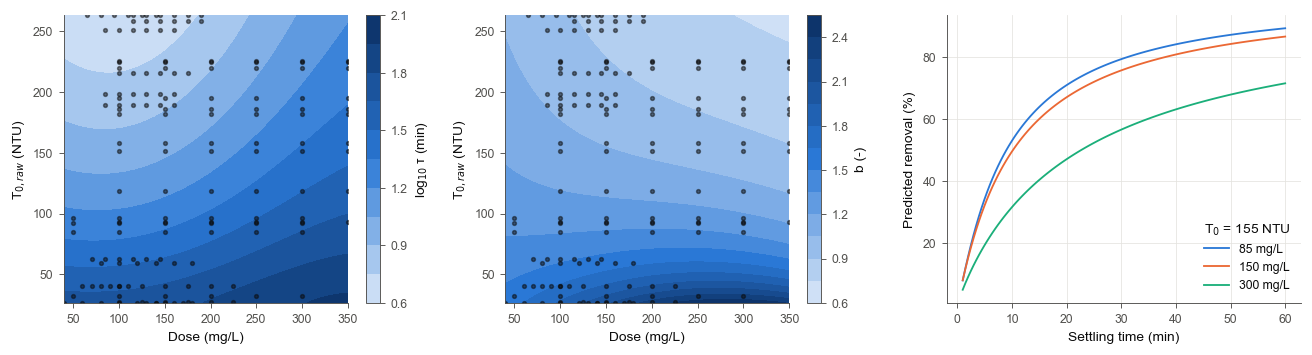

In [10]:
d_grid = np.linspace(jars["dose"].min(), jars["dose"].max(), 60)
t_grid = np.linspace(*np.quantile(jars["log_t0_raw"], [0.02, 0.98]), 60)
D, T = np.meshgrid(d_grid, t_grid)
P = hyb_params(np.column_stack([D.ravel(), T.ravel()]))
tau, b = P[:, 0].reshape(D.shape), P[:, 1].reshape(D.shape)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, Zg, lab in [(axes[0], np.log10(tau), "log$_{10}$ τ (min)"), (axes[1], b, "b (-)")]:
    cs = ax.contourf(D, 10 ** T, Zg, levels=12, cmap=style.SEQ)
    ax.scatter(jars["dose"], 10 ** jars["log_t0_raw"], s=6, color=style.INK, alpha=0.5)
    fig.colorbar(cs, ax=ax, label=lab)
    ax.set_xlabel("Dose (mg/L)")
    ax.set_ylabel("T$_{0,raw}$ (NTU)")
    ax.grid(False)
t0_med = jars["log_t0_raw"].median()
tt = np.linspace(1, 60, 120)
for i, dose in enumerate(np.quantile(jars["dose"], [0.1, 0.5, 0.9]).round()):
    pt = hyb_params(np.array([[dose, t0_med]]))[0]
    axes[2].plot(tt, 100 * (1 - kin.san(tt, 1.0, *pt)), color=style.COLORS[i], label=f"{dose:.0f} mg/L")
axes[2].set_xlabel("Settling time (min)")
axes[2].set_ylabel("Predicted removal (%)")
axes[2].legend(title=f"T$_0$ = {10 ** t0_med:.0f} NTU")
fig.tight_layout()
style.save(fig, "fig04_hybrid_parameters", "xai")
plt.show()

## 5. Save

In [11]:
imp.round(5).to_csv(MET / "07_shap_importance.csv")
ale_tab.round(5).to_csv(MET / "07_ale.csv", index=False)
key = {"shap_share": share.fillna(0).to_dict(),
       "tau_range_min": [round(float(tau.min()), 2), round(float(tau.max()), 2)],
       "b_range": [round(float(b.min()), 3), round(float(b.max()), 3)]}
(MET / "07_key_numbers.json").write_text(json.dumps(key, indent=2))
key

{'shap_share': {'ET core': {'dose': 0.189,
   'log_t0_raw': 0.455,
   'mtime': 0.0,
   'sed': 0.356,
   'speed': 0.0},
  'ET full': {'dose': 0.095,
   'log_t0_raw': 0.409,
   'mtime': 0.07,
   'sed': 0.296,
   'speed': 0.13},
  'Hybrid San + SVR': {'dose': 0.215,
   'log_t0_raw': 0.459,
   'mtime': 0.0,
   'sed': 0.326,
   'speed': 0.0}},
 'tau_range_min': [4.26, 93.85],
 'b_range': [0.726, 2.512]}